 ##REGRESYON##
regresyon Anaalizi
bir bağımlı değşkenşnn bir veya daha fala bağımzsız değişken ile olan ilikisini modellemeye yöneilik istTİKSEKL tekniktir.

değişkenler arasında ilişkiyi anlamma
geleeecektek, gözlemler iiçim tahmina yapmak
ekonmi finans 

TEMEL KAVRAMLAR
bağımlı değişke(y): sonnuç veya tahmin edilmek istenen değişkebün. Ev fiyatı vb.
bağımsız değş.: bağımlı değişlenii etliekuen. ev büyüklüğü, oda sayısı

Regrson modeli
Y=B0 +B1+ (episolon)


In [5]:
#Ev Fiyatlarını Tahmin Etme
import numpy as np 
import pandas as pd

data={"ev_boyutu":[50,60,70,80,90,100,110,120,130,140],
      "ev_fiyatı":[150000,180000,210000,240000,270000,300000,330000,360000,390000,420000]}

df=pd.DataFrame(data)
print(df)
 

   ev_boyutu  ev_fiyatı
0         50     150000
1         60     180000
2         70     210000
3         80     240000
4         90     270000
5        100     300000
6        110     330000
7        120     360000
8        130     390000
9        140     420000


In [9]:
X=df[["ev_boyutu"]]
y=df.ev_fiyatı
print(X)
print(y)

   ev_boyutu
0         50
1         60
2         70
3         80
4         90
5        100
6        110
7        120
8        130
9        140
0    150000
1    180000
2    210000
3    240000
4    270000
5    300000
6    330000
7    360000
8    390000
9    420000
Name: ev_fiyatı, dtype: int64


In [10]:
from sklearn.model_selection import train_test_split
XTrain,XTest,yTrain,yTest=train_test_split(X,y,test_size=0.20,random_state=28) #yüzde20luk kısmını test için ayırdık


In [11]:
from sklearn.linear_model import LinearRegression

model=LinearRegression()
model.fit(XTrain,yTrain)
yPred=model.predict(XTest)

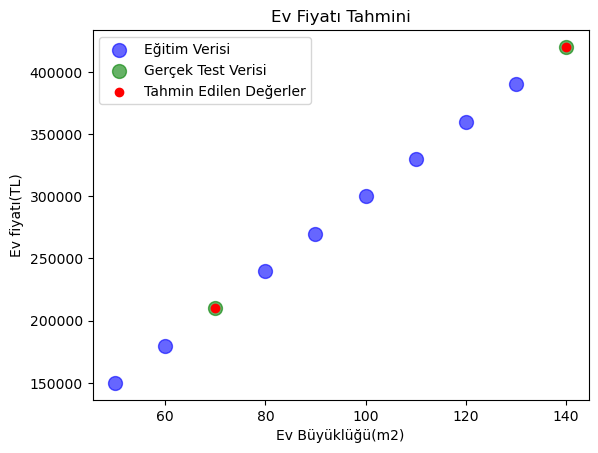

In [12]:
import matplotlib.pyplot as plt

#Sonuçları Gösterme
plt.scatter(XTrain, yTrain, color="blue", label="Eğitim Verisi", alpha=0.6, s=100)
plt.scatter(XTest, yTest, color="green", label="Gerçek Test Verisi", alpha=0.6, s=100)
plt.scatter(XTest, yPred, color="red", label="Tahmin Edilen Değerler")

plt.xlabel("Ev Büyüklüğü(m2)")
plt.ylabel("Ev fiyatı(TL)")
plt.title("Ev Fiyatı Tahmini")
plt.legend()
plt.show()


In [17]:
from sklearn.metrics import mean_squared_error,r2_score,mean_absolute_error
print(f"β0 (Sabit Terim):{model.intercept_}")
print(f"β1(Eğim Katsayısı: {model.coef_[0]})")

r2=r2_score(yTest,yPred)
print(f"R2 Score: {r2}")

#Adjusted R2 skoru
n = XTest.shape[0] #gözlem sayısı
p = XTest.shape[1] #bağımsız değişkenin sayısı

adjusted_r2 = 1 - (1 -r2) * (n-1)/(n-p-1)
print(f"Adjusted R2 Score: {adjusted_r2}") #nan çıktısı veriyor.(daha fazla veri istiyor)

#Mean Squared Error (MSE)
mse=mean_squared_error(yTest,yPred)
print(f"Mean Squared Error: {mse}")

#Robot Mean Squared Error (RMSE)
rmse=np.sqrt(mse)
print(f"Robot Mean Squared Error: {rmse}")

#Mean Absolute Error (MAE)
mae=mean_absolute_error(yTest,yPred)
print(f"Mean Absolute Error: {mae}")



β0 (Sabit Terim):-1.1641532182693481e-10
β1(Eğim Katsayısı: 3000.0000000000014)
R2 Score: 1.0
Adjusted R2 Score: nan
Mean Squared Error: 2.117582368135751e-21
Robot Mean Squared Error: 4.601719643932854e-11
Mean Absolute Error: 4.3655745685100555e-11


C:\Users\feyza\AppData\Local\Temp\ipykernel_9592\261661463.py:12: RuntimeWarning: invalid value encountered in scalar divide
  adjusted_r2 = 1 - (1 -r2) * (n-1)/(n-p-1)
